### Online Retail Sales Analysis and Prediction

## Project Overview

- Analyze historical transactions from a UK-based online retailer serving customers across different countries.
- Explore 541,909 records and 8 columns, including invoices, products, quantities, prices, customers, and countries.
- Identify missing values, duplicate records, cancellations, and unusual quantities or prices.
- Calculate transaction amounts and distinguish sales from returns and cancellations.
- Analyze sales trends, product performance, country-wise revenue, and customer purchasing patterns.
- Create visualizations and provide at least three actionable business insights.
- Prepare daily sales data and build features using historical information.
- Split the data chronologically into training and testing sets.
- Build and compare Linear Regression and Random Forest models using RMSE, MAE, and R².
- Document cleaning decisions, findings, model limitations, and recommendations.
- Create an additional Power BI dashboard to present key sales insights.

## Task 1: Data Cleaning

In [1]:
# Import libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import the Linear Regression model
from sklearn.linear_model import LinearRegression

# Import the model and a tool for copying preprocessing settings
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

# Import the hyperparameter search tool
from sklearn.model_selection import GridSearchCV

# Import time-ordered cross-validation
from sklearn.model_selection import TimeSeriesSplit

# Import the tool used to fill missing feature values
from sklearn.impute import SimpleImputer

# Import the tool used to encode calendar categories
from sklearn.preprocessing import OneHotEncoder

# Import tools for combining preprocessing steps and models
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)




print("All libraries have been imported successfully!")

All libraries have been imported successfully!


In [2]:
df = pd.read_excel(r"C:\Users\HP Pavilion 15 Touch\Downloads\online+retail\Online Retail.xlsx")

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Check data types and non-null counts
df.info()

# Count missing values
print("\nMissing values:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [4]:
# Count exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 5268


### Observation

Identified 5,268 exact duplicate rows. Retained the first occurrence of each and removed the repeated rows, leaving 536,641 records. This assumes identical repeated lines are duplicate entries; the dataset has no unique invoice-line identifier to verify this fully.

In [5]:
# Keep a copy of the original data
df_raw = df.copy()

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Rows after cleaning:", df.shape[0])
print("Remaining duplicates:", df.duplicated().sum())

Rows after cleaning: 536641
Remaining duplicates: 0


In [6]:
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("Negative UnitPrice:", (df["UnitPrice"] < 0).sum())
print("Zero UnitPrice:", (df["UnitPrice"] == 0).sum())

Negative Quantity: 10587
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 2510


In [7]:
display(df[df["UnitPrice"] < 0])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


### Observation:
Two negative-price records were identified as bad-debt accounting adjustments. They were saved separately and excluded from product sales analysis.

In [8]:
# Save accounting adjustments separately
bad_debt = df[df["Description"] == "Adjust bad debt"].copy()

# Exclude them from product sales data
df = df[df["Description"] != "Adjust bad debt"].copy()

print("Accounting adjustment rows:", len(bad_debt))
print("Remaining rows:", len(df))

Accounting adjustment rows: 3
Remaining rows: 536638


In [9]:
display(bad_debt[["InvoiceNo", "Description", "Quantity", "UnitPrice"]]
)

,InvoiceNo,Description,Quantity,UnitPrice
299982,A563185,Adjust bad debt,1,11062.06
299983,A563186,Adjust bad debt,1,-11062.06
299984,A563187,Adjust bad debt,1,-11062.06


### Observation 

Three bad-debt accounting adjustment records were saved separately and excluded from product sales analysis, leaving 536,638 records.

In [10]:
# View records with zero unit price
zero_price = df[df["UnitPrice"] == 0].copy()

display(
    zero_price[
        ["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID"]
    ].head(10)
)

,InvoiceNo,Description,Quantity,UnitPrice,CustomerID
622,536414,NaN,56,0.0,NaN
1970,536545,NaN,1,0.0,NaN
1971,536546,NaN,1,0.0,NaN
1972,536547,NaN,1,0.0,NaN
1987,536549,NaN,1,0.0,NaN
1988,536550,NaN,1,0.0,NaN
2024,536552,NaN,1,0.0,NaN
2025,536553,NaN,3,0.0,NaN
2026,536554,NaN,23,0.0,NaN
2406,536589,NaN,-10,0.0,NaN


In [11]:
print("Total zero-price records:", len(zero_price))

print("Missing descriptions:",
      zero_price["Description"].isna().sum())

print("Missing customer IDs:",
      zero_price["CustomerID"].isna().sum())

# Most common descriptions, including missing values
print(zero_price["Description"].value_counts(dropna=False).head(15))

Total zero-price records: 2510
Missing descriptions: 1454
Missing customer IDs: 2470
Description
NaN                              1454
check                             159
?                                  47
damages                            45
damaged                            43
found                              25
sold as set on dotcom              20
adjustment                         16
Damaged                            14
Unsaleable, destroyed.              9
thrown away                         9
FRENCH BLUE METAL DOOR SIGN 1       9
amazon                              8
FRENCH BLUE METAL DOOR SIGN 8       8
Found                               8
Name: count, dtype: int64


In [12]:
# Retain zero-price records separately
zero_price = df[df["UnitPrice"] == 0].copy()

# Keep records with a positive price
df = df[df["UnitPrice"] > 0].copy()

print("Remaining rows:", len(df))
print("Missing descriptions:", df["Description"].isna().sum())

Remaining rows: 534128
Missing descriptions: 0


### Oservation:

The 2,510 zero-price records included missing descriptions and stock-related notes such as “damages” and “adjustment.” These records were retained separately and excluded from paid sales analysis without imputing prices.

In [13]:
# Identify cancellation invoices
df["IsCancellation"] = (
    df["InvoiceNo"].astype(str).str.upper().str.startswith("C")
)

# Compare cancellations with negative quantities
display(pd.crosstab(
    df["IsCancellation"],
    df["Quantity"] < 0,
    rownames=["Cancellation"],
    colnames=["Negative Quantity"]
))

Negative Quantity,False,True
Cancellation,,
False,524877,0
True,0,9251


In [14]:
# Calculate the amount for each invoice line
df["LineAmount"] = df["Quantity"] * df["UnitPrice"]

display(
    df[["InvoiceNo", "Quantity", "UnitPrice",
        "IsCancellation", "LineAmount"]].head()
)

,InvoiceNo,Quantity,UnitPrice,IsCancellation,LineAmount
0,536365,6,2.55,False,15.30
1,536365,6,3.39,False,20.34
2,536365,8,2.75,False,22.00
3,536365,6,3.39,False,20.34
4,536365,6,3.39,False,20.34


### Observation

All 9,251 negative-quantity records have cancellation invoice numbers. The remaining 524,877 records have positive quantities and are not marked as cancellations. Cancellation records were retained to support separate sales and cancellation analysis

In [15]:
print("Missing Customer IDs:", df["CustomerID"].isna().sum())

print(
    "Missing percentage:",
    round(df["CustomerID"].isna().mean() * 100, 2)
)

Missing Customer IDs: 132564
Missing percentage: 24.82


In [16]:
# Flag records with an unknown customer
df["CustomerIDMissing"] = df["CustomerID"].isna()

# Store customer IDs as integers while preserving missing values
df["CustomerID"] = df["CustomerID"].astype("Int64")

print("CustomerID type:", df["CustomerID"].dtype)
print("Missing Customer IDs:", df["CustomerID"].isna().sum())

CustomerID type: Int64
Missing Customer IDs: 132564


### Observation

CustomerID is missing in 132,564 records (24.82%). These records were retained for sales analysis but will be excluded from customer-level analysis. A missing-value flag was added, and CustomerID was converted to a nullable integer type without imputing identifiers.

In [17]:
# Examine positive sales records separately from cancellations
sales_data = df[df["IsCancellation"] == False].copy()

display(
    sales_data[["Quantity", "UnitPrice", "LineAmount"]]
    .describe()
    .round(2)
)

,Quantity,UnitPrice,LineAmount
count,524877.00,524877.00,524877.00
mean,10.62,3.90,20.25
std,156.28,32.71,271.27
min,1.00,0.00,0.00
25%,1.00,1.25,3.90
50%,4.00,2.08,9.92
75%,11.00,4.13,17.70
max,80995.00,13541.33,168469.60


In [18]:
display(
    sales_data.nlargest(5, "Quantity")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "LineAmount"]
    ]
)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineAmount
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92


In [19]:
display(
    df[
        df["StockCode"].astype(str).isin(["23843", "23166"])
        & (df["Quantity"].abs() > 70000)
    ][
        ["InvoiceNo", "StockCode", "Quantity",
         "UnitPrice", "CustomerID", "InvoiceDate"]
    ]
)

,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID,InvoiceDate
61619,541431,23166,74215,1.04,12346,2011-01-18 10:01:00
61624,C541433,23166,-74215,1.04,12346,2011-01-18 10:17:00
540421,581483,23843,80995,2.08,16446,2011-12-09 09:15:00
540422,C581484,23843,-80995,2.08,16446,2011-12-09 09:27:00


### Observation
The two largest quantity transactions were followed by matching cancellations on the same day. Product, customer, price, and quantity matched within each pair, resulting in zero net amounts. Both sales and cancellation records were retained.

In [20]:
display(
    sales_data.nlargest(5, "UnitPrice")[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "LineAmount"]
    ]
)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,LineAmount
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33
173382,551697,POST,POSTAGE,1,8142.75,8142.75
297723,562955,DOT,DOTCOM POSTAGE,1,4505.17,4505.17
268028,560373,M,Manual,1,4287.63,4287.63
422351,573077,M,Manual,1,4161.06,4161.06


### Observation:
The highest unit prices included fees, postage charges, and manual entries rather than ordinary products. These records were flagged for separate review instead of being removed solely because of their high prices.

In [21]:
# Flag fees, postage, and manual entries
special_codes = ["AMAZONFEE", "POST", "DOT", "M"]

df["IsSpecialEntry"] = (
    df["StockCode"].astype(str).str.strip().isin(special_codes)
)

print(
    df.loc[df["IsSpecialEntry"], "Description"]
    .value_counts()
)

Description
POSTAGE           1252
DOTCOM POSTAGE     707
Manual             560
AMAZON FEE          34
Name: count, dtype: int64


In [22]:
# Check positive quantities, excluding flagged special entries
product_sales = df[
    (~df["IsCancellation"]) & (~df["IsSpecialEntry"])
].copy()

q1 = product_sales["Quantity"].quantile(0.25)
q3 = product_sales["Quantity"].quantile(0.75)

iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

print("Upper limit:", upper_limit)
print(
    "Rows above upper limit:",
    (product_sales["Quantity"] > upper_limit).sum()
)

Upper limit: 28.5
Rows above upper limit: 26815


### Observation:
The IQR method identified 26,815 positive product-sales records with quantities above 28.5. These records were flagged and retained because high quantities may represent bulk purchases rather than errors.

In [23]:
# Flag high quantities in the positive product-sales subset
df["HighQuantityFlag"] = (
    (~df["IsCancellation"])
    & (~df["IsSpecialEntry"])
    & (df["Quantity"] > upper_limit)
)

print("Flagged rows:", df["HighQuantityFlag"].sum())

Flagged rows: 26815


In [24]:
for column in ["Country", "Description"]:
    text = df[column].astype("string")
    print(column, ":", (text != text.str.strip()).sum())

Country : 0
Description : 112312


### Observation:
Removed leading and trailing spaces from 112,312 product descriptions. No such spaces were found in the Country column.

In [25]:
# Remove leading and trailing spaces
df["Description"] = df["Description"].str.strip()

# Verify
print(
    "Remaining extra spaces:",
    (df["Description"] != df["Description"].str.strip()).sum()
)

Remaining extra spaces: 0


In [26]:
# Count unique country labels
print("Number of countries:", df["Country"].nunique())

# Display country labels in alphabetical order
print(sorted(df["Country"].unique()))

Number of countries: 38
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'EIRE', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'RSA', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'USA', 'United Arab Emirates', 'United Kingdom', 'Unspecified']


In [27]:
# Standardize abbreviated country names
df["Country"] = df["Country"].replace({
    "EIRE": "Ireland",
    "RSA": "South Africa",
    "USA": "United States"
})

# Check the number of records with an unspecified country
print("Unspecified country records:",
      (df["Country"] == "Unspecified").sum())

# Display the updated country and region labels
print(sorted(df["Country"].unique()))

Unspecified country records: 442
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Ireland', 'Israel', 'Italy', 'Japan', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'United Arab Emirates', 'United Kingdom', 'United States', 'Unspecified']


### Observation:
Standardized EIRE, RSA, and USA to Ireland, South Africa, and United States. Retained 442 records labelled “Unspecified” without assigning an assumed country.

In [28]:
# Check the date column's data type
print("Date type:", df["InvoiceDate"].dtype)

# Count missing dates
print("Missing dates:", df["InvoiceDate"].isna().sum())

# Find the earliest and latest transaction dates
print("First date:", df["InvoiceDate"].min())
print("Last date:", df["InvoiceDate"].max())

Date type: datetime64[ns]
Missing dates: 0
First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:50:00


### Observation:
InvoiceDate is already in datetime format with no missing values. Transactions span December 1, 2010 to December 9, 2011. December 2011 is incomplete and should be considered when comparing monthly sales.

In [29]:
# Original transaction columns, excluding added flags
original_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]

# Check for duplicates after text standardization
print(
    "Duplicates after standardization:",
    df.duplicated(subset=original_columns).sum()
)

Duplicates after standardization: 0


In [30]:
# Store invoice numbers as text; preserve cancellation codes such as C541433
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()

# Store product codes as text; some codes contain letters
df["StockCode"] = df["StockCode"].astype("string").str.strip()

# Convert customer IDs to text while preserving missing values
df["CustomerID"] = df["CustomerID"].astype("string")

# Verify the updated data types
print(df[["InvoiceNo", "StockCode", "CustomerID"]].dtypes)

# Confirm missing customer IDs are still preserved
print("Missing Customer IDs:", df["CustomerID"].isna().sum())

InvoiceNo     string[python]
StockCode     string[python]
CustomerID    string[python]
dtype: object
Missing Customer IDs: 132564


In [31]:
# Rename columns using consistent snake_case names
df = df.rename(columns={
    "InvoiceNo": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "UnitPrice": "unit_price",
    "CustomerID": "customer_id",
    "Country": "country",
    "IsCancellation": "is_cancellation",
    "LineAmount": "line_amount",
    "CustomerIDMissing": "customer_id_missing",
    "IsSpecialEntry": "is_special_entry",
    "HighQuantityFlag": "high_quantity_flag"
})

# Display the updated column names and dataset shape
print(df.columns.tolist())
print("Shape:", df.shape)

['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancellation', 'line_amount', 'customer_id_missing', 'is_special_entry', 'high_quantity_flag']
Shape: (534128, 13)


In [32]:
# Check missing values in all columns
print("Missing values:")
print(df.isna().sum())

# Confirm all retained prices are positive
print("\nZero or negative prices:",
      (df["unit_price"] <= 0).sum())

# Confirm cancellation flags match negative quantities
print("Cancellation mismatches:",
      (df["is_cancellation"] != (df["quantity"] < 0)).sum())

# Confirm the customer-missing flag is accurate
print("Customer flag mismatches:",
      (df["customer_id_missing"] != df["customer_id"].isna()).sum())

Missing values:
invoice_no                  0
stock_code                  0
description                 0
quantity                    0
invoice_date                0
unit_price                  0
customer_id            132564
country                     0
is_cancellation             0
line_amount                 0
customer_id_missing         0
is_special_entry            0
high_quantity_flag          0
dtype: int64

Zero or negative prices: 0
Cancellation mismatches: 0
Customer flag mismatches: 0


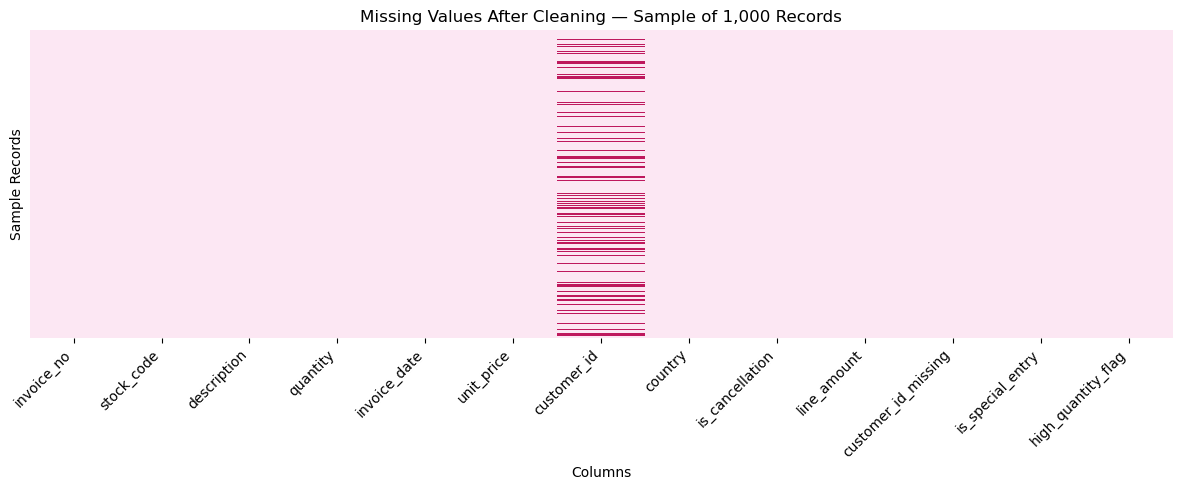

In [33]:

# Select a reproducible sample for visualization
sample_data = df.sample(n=1000, random_state=42)

# Show where values are missing
plt.figure(figsize=(12, 5))

sns.heatmap(
    sample_data.isna(),
    cbar=False,
    yticklabels=False,
    cmap=sns.color_palette(["#FCE7F3", "#BE185D"], as_cmap=True)
)

# Add chart title and axis labels
plt.title("Missing Values After Cleaning — Sample of 1,000 Records")
plt.xlabel("Columns")
plt.ylabel("Sample Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observation:
Final checks found no non-positive prices or inconsistencies in the cancellation and customer-missing flags. Missing customer IDs were intentionally retained for sales analysis. The heatmap displays missingness in a sample; exact counts were validated using the full dataset.

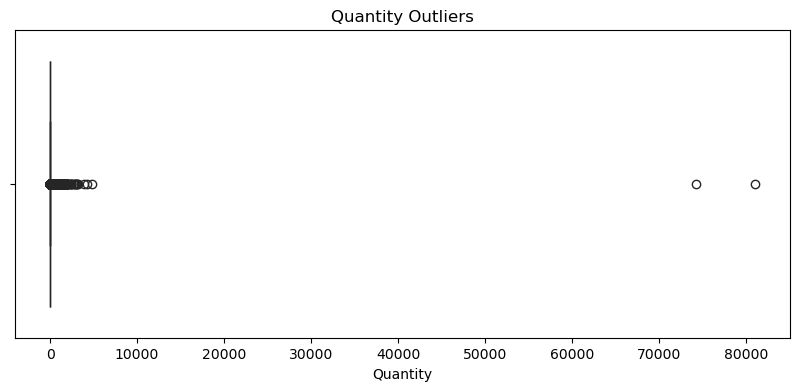

In [34]:
# Create a fresh copy using the updated column names
product_sales = df[
    (~df["is_cancellation"]) & (~df["is_special_entry"])
].copy()

# Show quantity distribution and potential outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=product_sales["quantity"], color="purple")
plt.title("Quantity Outliers")
plt.xlabel("Quantity")
plt.show()

### Observation:
Quantity is strongly right-skewed, with most records containing small quantities and a few containing very large quantities. Potential outliers were retained because large quantities may represent bulk orders or transactions with matching cancellations.

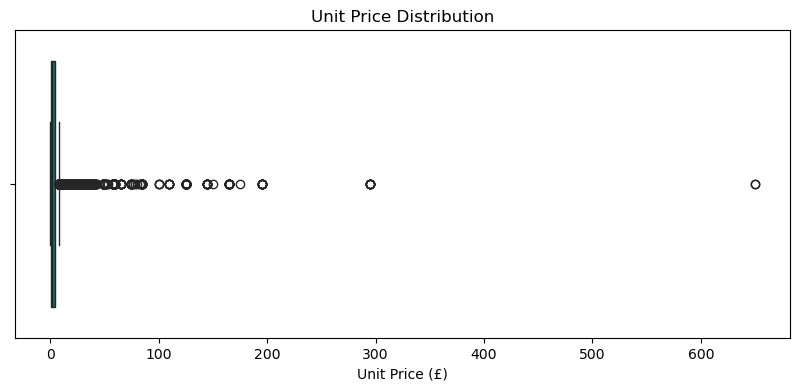

In [35]:
# Show unit prices and potential outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=product_sales["unit_price"], color="teal")

# Add chart title and axis label
plt.title("Unit Price Distribution")
plt.xlabel("Unit Price (£)")
plt.show()

### Observation:
Unit prices are strongly right-skewed. Most records have low prices, while a few have substantially higher prices. These records require investigation before any removal.

In [36]:
# Show the five records with the highest unit prices
display(
    product_sales.nlargest(5, "unit_price")[
        ["stock_code", "description", "quantity", "unit_price"]
    ]
)

,stock_code,description,quantity,unit_price
222680,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5
222682,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5
4989,22655,VINTAGE RED KITCHEN CABINET,1,295.0
32484,22655,VINTAGE RED KITCHEN CABINET,1,295.0
51636,22655,VINTAGE RED KITCHEN CABINET,1,295.0


In [37]:
# Review sales and cancellations for the highest-priced product
display(
    df.loc[
        df["stock_code"] == "22502",
        ["invoice_no", "description", "quantity",
         "unit_price", "customer_id", "invoice_date"]
    ].sort_values("invoice_date")
)

,invoice_no,description,quantity,unit_price,customer_id,invoice_date
249,536392,PICNIC BASKET WICKER SMALL,4,5.95,13705,2010-12-01 10:29:00
381,536401,PICNIC BASKET WICKER SMALL,2,5.95,15862,2010-12-01 11:21:00
3526,536635,PICNIC BASKET WICKER SMALL,8,5.95,15955,2010-12-02 11:22:00
3642,536638,PICNIC BASKET WICKER SMALL,4,5.95,16244,2010-12-02 11:41:00
4916,536821,PICNIC BASKET WICKER SMALL,3,5.95,17757,2010-12-02 17:17:00
...,...,...,...,...,...,...
319768,564895,PICNIC BASKET WICKER SMALL,1,5.95,15596,2011-08-31 10:55:00
321571,565152,PICNIC BASKET WICKER SMALL,2,5.95,17799,2011-09-01 14:42:00
325372,565438,PICNIC BASKET WICKER SMALL,2,5.95,17229,2011-09-04 13:56:00
340148,566607,PICNIC BASKET WICKER SMALL,2,5.95,13032,2011-09-13 16:40:00


In [38]:
# Select this product's high-price records only
high_price = df[
    (df["stock_code"] == "22502")
    & (df["unit_price"] > 600)
]

# Display sales and cancellations without hiding rows
print(
    high_price[
        ["invoice_no", "description", "quantity",
         "unit_price", "customer_id", "invoice_date"]
    ].to_string(index=False)
)

invoice_no                    description  quantity  unit_price customer_id        invoice_date
    556444 PICNIC BASKET WICKER 60 PIECES        60       649.5       15098 2011-06-10 15:28:00
    556446 PICNIC BASKET WICKER 60 PIECES         1       649.5       15098 2011-06-10 15:33:00


In [39]:
# Check all same-day entries for this customer and product
display(df[
    (df["stock_code"] == "22502")
    & (df["customer_id"] == "15098")
    & (df["invoice_date"].dt.date == pd.Timestamp("2011-06-10").date())
][["invoice_no", "description", "quantity", "unit_price", "line_amount"]])

,invoice_no,description,quantity,unit_price,line_amount
222670,556442,PICNIC BASKET WICKER SMALL,60,4.95,297.0
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0
222682,556446,PICNIC BASKET WICKER 60 PIECES,1,649.50,649.5
222692,C556448,PICNIC BASKET WICKER SMALL,-60,4.95,-297.0


### Observation 
A £297 sale had a matching cancellation. Two additional entries priced at £649.50 had different descriptions and no matching cancellation in the reviewed same-day records. These entries were flagged and retained because their correctness could not be verified.

In [40]:
# Flag the reviewed high-price entries for further investigation
df["price_review_flag"] = (
    (df["stock_code"] == "22502")
    & (df["unit_price"] > 600)
)

# Verify the number of flagged records
print("Price review records:", df["price_review_flag"].sum())

Price review records: 2


In [41]:
# Compare the original and cleaned datasets
comparison = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Customer IDs",
        "Missing Descriptions",
        "Zero Prices",
        "Negative Prices"
    ],
    "Before": [
        len(df_raw),
        df_raw.shape[1],
        df_raw["CustomerID"].isna().sum(),
        df_raw["Description"].isna().sum(),
        (df_raw["UnitPrice"] == 0).sum(),
        (df_raw["UnitPrice"] < 0).sum()
    ],
    "After": [
        len(df),
        df.shape[1],
        df["customer_id"].isna().sum(),
        df["description"].isna().sum(),
        (df["unit_price"] == 0).sum(),
        (df["unit_price"] < 0).sum()
    ]
})

# Display the cleaning comparison
display(comparison)

,Metric,Before,After
0,Rows,541909,534128
1,Columns,8,14
2,Missing Customer IDs,135080,132564
3,Missing Descriptions,1454,0
4,Zero Prices,2515,0
5,Negative Prices,2,0


In [42]:
# Check duplicates using only the original transaction fields
original_cols = [
    "invoice_no", "stock_code", "description", "quantity",
    "invoice_date", "unit_price", "customer_id", "country"
]

# Display the final duplicate count and dataset size
print("Final duplicates:", df.duplicated(subset=original_cols).sum())
print("Final shape:", df.shape)

Final duplicates: 0
Final shape: (534128, 14)


In [43]:
# Save the cleaned dataset without the row index
df.to_csv("online_retail_cleaned.csv", index=False)

# Save excluded records for reference
bad_debt.to_csv("bad_debt_adjustments.csv", index=False)
zero_price.to_csv("zero_price_records.csv", index=False)

# Save the before-and-after comparison
comparison.to_csv("cleaning_comparison.csv", index=False)

print("All CSV files saved successfully!")

All CSV files saved successfully!


### Data Cleaning Summary

- Loaded 541,909 records and 8 columns.
- Removed 5,268 exact duplicate rows, retaining the first occurrence.
- Saved 3 bad-debt adjustments and 2,510 zero-price records separately and excluded them from paid sales analysis.
- Retained 9,251 cancellation records to support net sales analysis.
- Preserved 132,564 missing Customer IDs without assigning artificial identifiers.
- Removed leading and trailing spaces from 112,312 descriptions.
- Standardized country abbreviations and column names.
- Converted identifier columns to text while preserving missing values.
- Calculated line_amount and added missing-value, cancellation, special-entry, and review flags.
- Used IQR to flag 26,815 high-quantity records and separately flagged 2 high-price records. Retained them pending reliable evidence for removal.
- Validated the final dataset: 534,128 rows, 14 columns, and no exact duplicates.
- Exported the cleaned data, excluded records, and comparison table.
- Deferred categorical encoding to model preparation, where it will be fitted using training data.

### .Challenges Faced and Solutions
- Missing Customer IDs: Retained these records for sales analysis without assigning artificial IDs. They will be excluded from customer-level analysis.
- Negative Quantities: Checked cancellation invoice numbers and confirmed that all retained negative-quantity records were cancellations. Preserved them for net sales analysis.
- Zero and Negative Prices: Reviewed descriptions to identify stock-related entries and bad-debt adjustments. Saved excluded records separately instead of replacing prices with assumed values.
- Extreme Quantities: Investigated large transactions and identified matching cancellations for the two largest orders. Used IQR flags without automatically deleting bulk purchases.
- Inconsistent Product Descriptions and Prices: Found different descriptions under the same stock code. Flagged two unusually high-price records because their correctness could not be verified.
- Column Naming Errors: Encountered a KeyError when an older DataFrame copy contained previous column names. Recreated the subset from the updated DataFrame.

## Task 2: Exploratory Data Analysis (EDA)

Explore sales patterns, cancellations, product performance, and country-wise revenue to identify actionable business insights.

In [44]:
# Summarize numeric columns
display(df[["quantity", "unit_price", "line_amount"]].describe().round(2))

# Summarize country and product information
display(df[["country", "stock_code", "description"]].describe())

,quantity,unit_price,line_amount
count,534128.00,534128.00,534128.00
mean,9.92,4.68,18.23
std,216.45,93.87,380.65
min,-80995.00,0.00,-168469.60
25%,1.00,1.25,3.75
50%,3.00,2.10,9.90
75%,10.00,4.13,17.57
max,80995.00,38970.00,168469.60


,country,stock_code,description
count,534128,534128,534128
unique,38,3937,4030
top,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER
freq,487805,2295,2353


### Descriptive Statistics Observations
- The dataset contains 534,128 transaction lines, including sales, cancellations, and flagged special entries.
- Median quantity is 3, while mean quantity is 9.92, indicating the influence of large transactions.
- Quantities range from −80,995 to 80,995. Negative quantities represent cancellations.
- Median line amount is £9.90. Negative amounts reduce net sales.
- The minimum unit price appears as £0.00 due to rounding; validation confirmed that all retained prices are positive.
- The maximum unit price of £38,970 requires investigation. This summary includes special entries that were excluded from the earlier product-only boxplot.
- There are 38 country/region labels, with the United Kingdom appearing in 487,805 transaction lines.
- There are 3,937 stock codes and 4,030 descriptions. Product descriptions are not a reliable unique product identifier.
- The most frequent description is WHITE HANGING HEART T-LIGHT HOLDER. Frequency alone does not establish the highest-selling product by quantity or revenue.

In [45]:
# Review the three highest unit prices in the full cleaned dataset
display(
    df.nlargest(3, "unit_price")[
        ["invoice_no", "stock_code", "description",
         "quantity", "unit_price", "is_special_entry"]
    ]
)

,invoice_no,stock_code,description,quantity,unit_price,is_special_entry
222681,C556445,M,Manual,-1,38970.00,True
524602,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,True
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,True


In [46]:
# Exclude flagged special entries; retain product sales and cancellations
eda = df[~df["is_special_entry"]].copy()

# Check the size of the analysis dataset
print("EDA shape:", eda.shape)

# Summarize product transaction values
display(
    eda[["quantity", "unit_price", "line_amount"]]
    .describe()
    .round(2)
)

EDA shape: (531575, 14)


,quantity,unit_price,line_amount
count,531575.00,531575.00,531575.00
mean,9.95,3.35,18.35
std,216.94,6.96,369.67
min,-80995.00,0.00,-168469.60
25%,1.00,1.25,3.75
50%,3.00,2.08,9.90
75%,10.00,4.13,17.40
max,80995.00,1867.86,168469.60


In [47]:
# Review the highest prices remaining in the EDA subset
display(
    eda.nlargest(5, "unit_price")[
        ["invoice_no", "stock_code", "description",
         "quantity", "unit_price"]
    ]
)

,invoice_no,stock_code,description,quantity,unit_price
150591,C549452,D,Discount,-1,1867.86
528087,C580726,CRUK,CRUK Commission,-1,1100.44
64573,C541653,BANK CHARGES,Bank Charges,-1,1050.15
467437,C576338,CRUK,CRUK Commission,-1,1038.75
508561,C579195,CRUK,CRUK Commission,-1,987.14


In [48]:
# Update the list of identified non-product codes
special_codes = [
    "AMAZONFEE", "POST", "DOT", "M",
    "D", "CRUK", "BANK CHARGES"
]

# Update the flag in the main dataset
df["is_special_entry"] = df["stock_code"].isin(special_codes)

# Recreate the product-analysis subset, retaining cancellations
eda = df[~df["is_special_entry"]].copy()

# Check the remaining highest prices
display(
    eda.nlargest(5, "unit_price")[
        ["stock_code", "description", "quantity", "unit_price"]
    ]
)

,stock_code,description,quantity,unit_price
222680,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5
222682,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5
242589,S,SAMPLES,-1,570.0
4989,22655,VINTAGE RED KITCHEN CABINET,1,295.0
32484,22655,VINTAGE RED KITCHEN CABINET,1,295.0


In [49]:
# Flag sample entries along with previously identified special entries
df["is_special_entry"] = (
    df["is_special_entry"] | df["stock_code"].eq("S")
)

# Refresh the product-analysis subset
eda = df[~df["is_special_entry"]].copy()

# Save the updated flags in the cleaned CSV
df.to_csv("online_retail_cleaned.csv", index=False)

# Display the updated analysis size
print("EDA shape:", eda.shape)

EDA shape: (531383, 14)


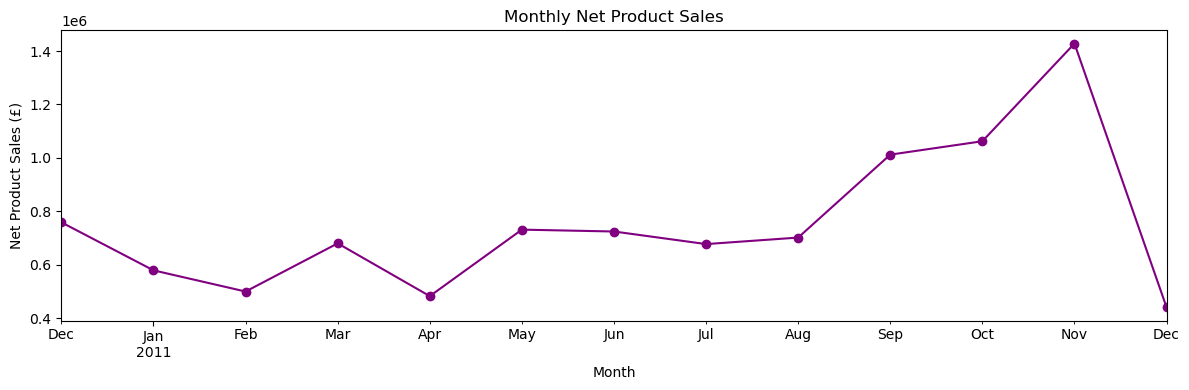

In [50]:
# Add sales and cancellation amounts for each month
monthly_sales = (
    eda.set_index("invoice_date")["line_amount"]
    .resample("MS")
    .sum()
)

# Plot monthly net product sales
plt.figure(figsize=(12, 4))
monthly_sales.plot(marker="o", color="purple")

# Add chart title and labels
plt.title("Monthly Net Product Sales")
plt.xlabel("Month")
plt.ylabel("Net Product Sales (£)")
plt.tight_layout()
plt.show()

### Observations 
- November 2011 recorded the highest net product sales, approximately £1.43 million.
- April 2011 had the lowest sales among complete months, approximately £0.48 million.
- Sales remained relatively stable from May to August, followed by strong growth from September to November.
- The year-end increase may reflect seasonal demand, but the chart alone does not confirm its cause.
- December 2011 is incomplete, covering only December 1–9. Its lower total should not be interpreted as a full-month sales decline.

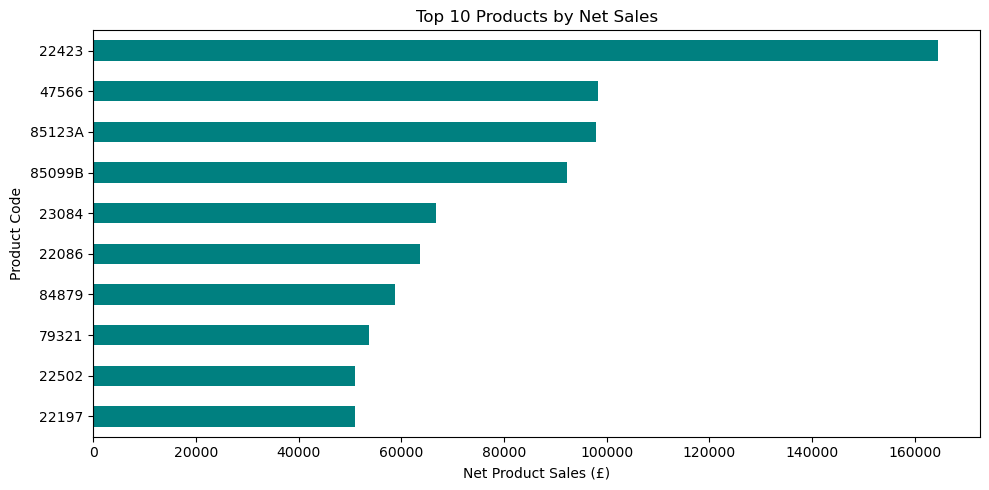

In [51]:
# Add sales and cancellation amounts for each product code
top_products = (
    eda.groupby("stock_code")["line_amount"]
    .sum()
    .nlargest(10)
)

# Display the highest-selling product codes
plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind="barh", color="teal")

# Add chart title and labels
plt.title("Top 10 Products by Net Sales")
plt.xlabel("Net Product Sales (£)")
plt.ylabel("Product Code")
plt.tight_layout()
plt.show()

### Observations
- Product 22423 has the highest net sales, approximately £164,000.
- Products 47566 and 85123A rank second and third, each generating approximately £98,000.
- The leading product generates substantially more net sales than the other products shown.
- Product 22502 appears in the top 10, but its total includes the two flagged high-price records. Its ranking requires further review.
- These rankings reflect sales value after cancellations, not units sold or profit.

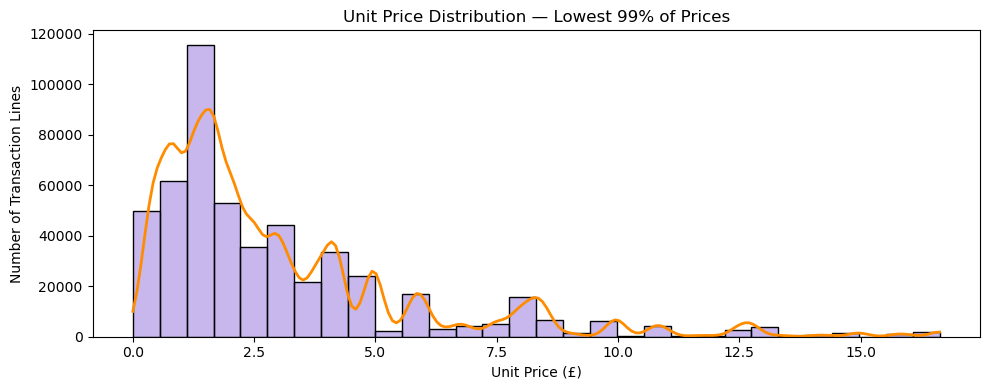

In [52]:
# Select positive product sales for the price distribution
prices = eda.loc[~eda["is_cancellation"], "unit_price"]

# Focus on the lowest 99% of prices for a readable chart
limit = prices.quantile(0.99)

# Plot price frequency with a smooth distribution curve
plt.figure(figsize=(10, 4))
ax=sns.histplot(prices[prices <= limit], bins=30, kde=True, color="mediumpurple")

# Change the KDE line color to dark orange
ax.lines[-1].set_color("darkorange")
ax.lines[-1].set_linewidth(2)

# Add chart title and labels
plt.title("Unit Price Distribution — Lowest 99% of Prices")
plt.xlabel("Unit Price (£)")
plt.ylabel("Number of Transaction Lines")
plt.tight_layout()
plt.show()

### Observations
- Unit prices are right-skewed, with most transaction lines concentrated at lower prices.
- The tallest bar is around £1–£2, indicating a frequently occurring price range.
- Transaction lines generally become less frequent as unit price increases.
- Multiple peaks suggest commonly repeated price points.
- The highest-priced 1% of records were excluded only from this visualization to improve readability; they remain in the dataset.

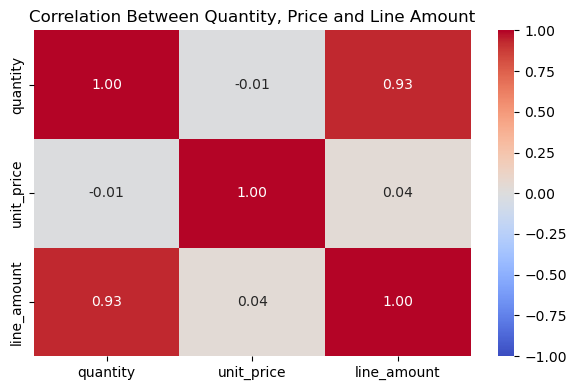

In [53]:
# Calculate correlations between numeric columns
correlation = eda[["quantity", "unit_price", "line_amount"]].corr()

# Display correlation values in a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

# Add chart title
plt.title("Correlation Between Quantity, Price and Line Amount")
plt.tight_layout()
plt.show()

### Observations 
- Quantity and line amount show a strong positive correlation (0.93). This partly reflects the formula: line_amount = quantity × unit_price.
- Quantity and unit price have almost no linear correlation (−0.01).
- Unit price and line amount show a very weak positive correlation (0.04).
- Extreme transactions and cancellations may influence these correlations.
- Correlation does not establish causation, and a near-zero value does not rule out a nonlinear relationship.

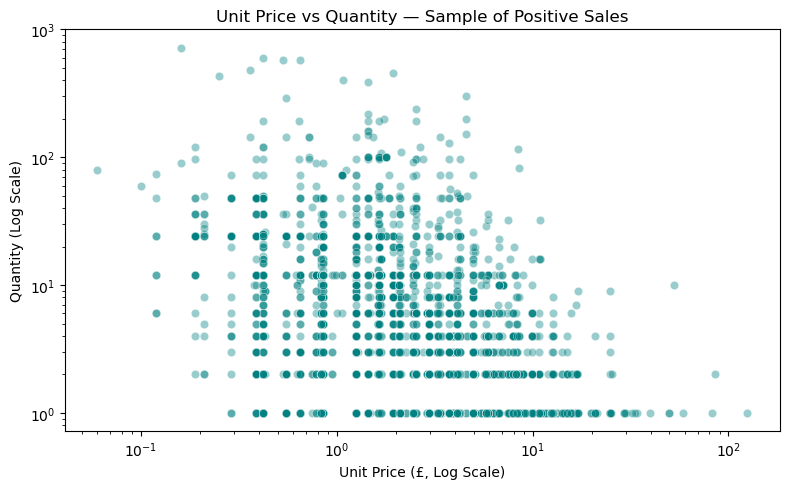

In [54]:
# Select positive product sales
positive_sales = eda[~eda["is_cancellation"]]

# Sample up to 5,000 records to reduce overlapping points
sample = positive_sales.sample(
    n=min(5000, len(positive_sales)),
    random_state=42
)

# Plot price against quantity
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample,
    x="unit_price",
    y="quantity",
    color="teal",
    alpha=0.4
)

# Use log scales to make small and large values visible
plt.xscale("log")
plt.yscale("log")

# Add chart title and labels
plt.title("Unit Price vs Quantity — Sample of Positive Sales")
plt.xlabel("Unit Price (£, Log Scale)")
plt.ylabel("Quantity (Log Scale)")
plt.tight_layout()
plt.show()

### Observations 
- Most sampled transaction lines have low quantities, often between 1 and 12 units.
- Large quantities occur mainly at lower unit prices, while higher-priced items generally appear in smaller quantities.
- Horizontal bands reflect repeated integer quantities, such as 1, 2, and 6 units.
- Both axes use logarithmic scales, allowing small and large values to remain visible.
- These observations apply to a sample of positive sales, excluding cancellations. They do not prove that lower prices cause larger purchases.

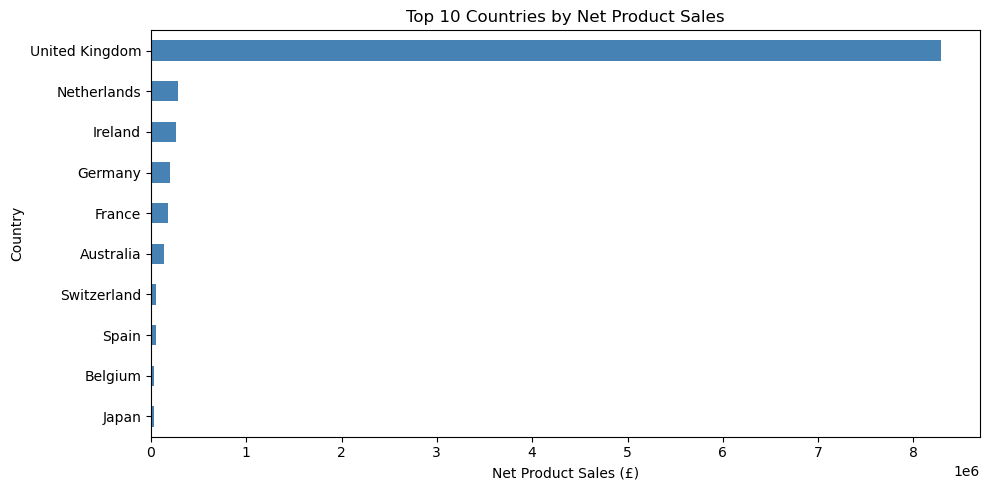

country
United Kingdom    8283553.72
Netherlands        283479.54
Ireland            264555.02
Germany            200619.66
France             182262.60
Australia          136922.50
Switzerland         52483.05
Spain               51746.65
Belgium             36662.96
Japan               35419.79
Name: line_amount, dtype: float64


In [55]:
# Calculate net product sales for each country
country_sales = (
    eda.groupby("country")["line_amount"]
    .sum()
    .nlargest(10)
)

# Show the top 10 countries
plt.figure(figsize=(10, 5))
country_sales.sort_values().plot(kind="barh", color="steelblue")

# Add chart title and labels
plt.title("Top 10 Countries by Net Product Sales")
plt.xlabel("Net Product Sales (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# Display exact values for interpretation
print(country_sales.round(2))

### Observations 
- The United Kingdom dominates net product sales, generating approximately £8.28 million.
- The Netherlands (£283,479.54) and Ireland (£264,555.02) are the largest overseas markets.
- Germany (£200,619.66) and France (£182,262.60) also contribute to international sales.
- Sales are heavily concentrated in the UK, indicating dependence on the domestic market.
- The UK’s large total makes differences between overseas markets difficult to see on this chart.

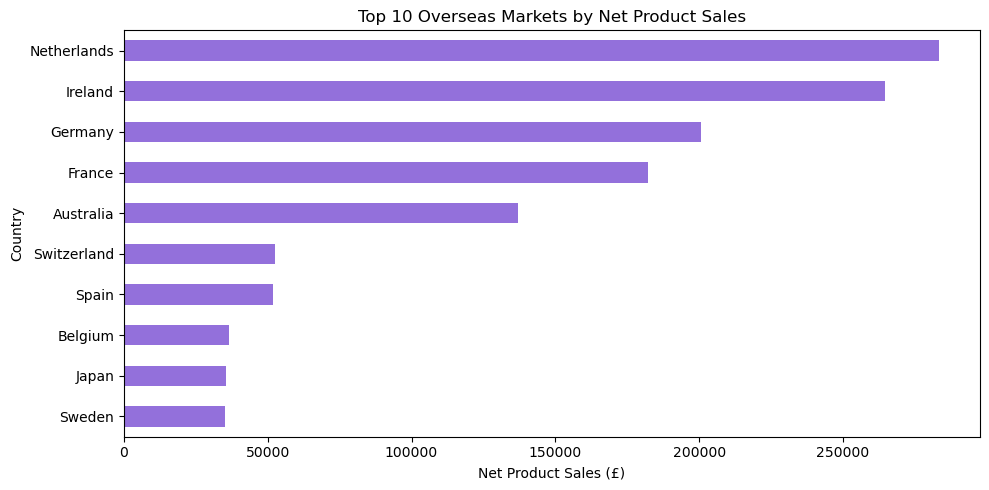

country
Netherlands    283479.54
Ireland        264555.02
Germany        200619.66
France         182262.60
Australia      136922.50
Switzerland     52483.05
Spain           51746.65
Belgium         36662.96
Japan           35419.79
Sweden          35166.41
Name: line_amount, dtype: float64


In [56]:
# Exclude the UK and the unknown country label
overseas = eda[
    ~eda["country"].isin(["United Kingdom", "Unspecified"])
]

# Calculate the top 10 overseas markets by net product sales
overseas_sales = (
    overseas.groupby("country")["line_amount"]
    .sum()
    .nlargest(10)
)

# Plot overseas sales for easier comparison
plt.figure(figsize=(10, 5))
overseas_sales.sort_values().plot(kind="barh", color="mediumpurple")

# Add chart title and labels
plt.title("Top 10 Overseas Markets by Net Product Sales")
plt.xlabel("Net Product Sales (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

# Display exact sales values
print(overseas_sales.round(2))

### Observations 
- The Netherlands leads overseas markets with £283,479.54, followed by Ireland (£264,555.02).
- Germany and France rank third and fourth.
- Australia ranks fifth with £136,922.50, substantially ahead of Switzerland.
- Switzerland and Spain have similar net product sales, at approximately £52,000 each.
- Excluding the UK makes differences between overseas markets easier to compare.

In [57]:
# Add amounts from positive sales
gross_sales = eda.loc[
    ~eda["is_cancellation"], "line_amount"
].sum()

# Show cancellation amounts as a positive total
cancelled_amount = -eda.loc[
    eda["is_cancellation"], "line_amount"
].sum()

# Subtract cancellations from gross sales
net_sales = gross_sales - cancelled_amount

# Calculate cancellation amount as a percentage of gross sales
cancellation_percent = cancelled_amount / gross_sales * 100

# Display the results
print("Gross Product Sales (£):", round(gross_sales, 2))
print("Cancellation Amount (£):", round(cancelled_amount, 2))
print("Net Product Sales (£):", round(net_sales, 2))
print("Cancellation Amount (%):", round(cancellation_percent, 2))

Gross Product Sales (£): 10254958.68
Cancellation Amount (£): 475966.16
Net Product Sales (£): 9778992.52
Cancellation Amount (%): 4.64


### Impact of Cancellations on Product Sales
- Gross product sales totalled £10,254,958.68.
- Recorded cancellations reduced this amount by £475,966.16, equivalent to 4.64% of gross product sales.
- Net product sales after cancellations were £9,778,992.52.
- These figures exclude flagged special entries and include the two unresolved high-price records. They represent product transaction amounts, not profit.

customer_id
14646    278778.02
18102    259657.30
17450    189575.53
14911    132893.24
12415    123638.18
14156    114335.77
17511     88138.20
16684     65920.12
13694     62961.54
16029     60369.93
Name: line_amount, dtype: float64


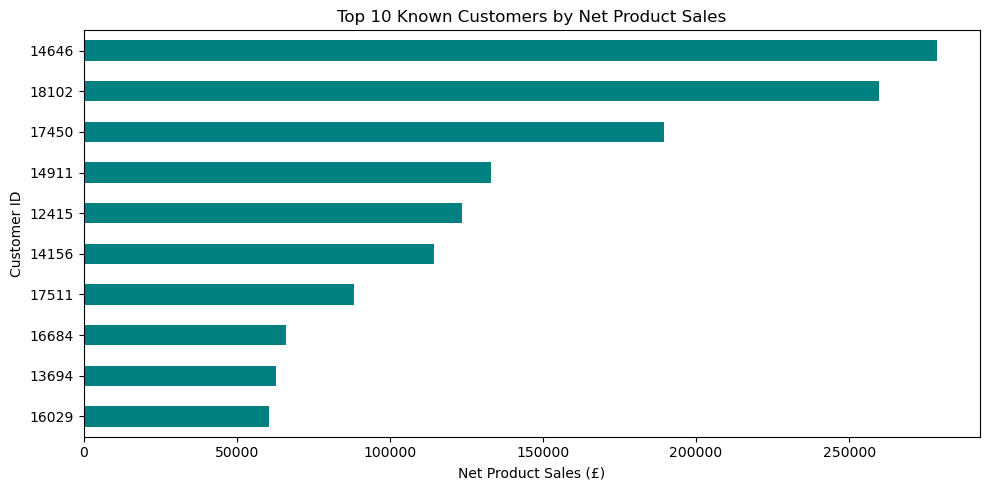

In [58]:
# Use only records with a known customer ID
customer_data = eda.dropna(subset=["customer_id"])

# Calculate the top 10 customers by net product sales
top_customers = (
    customer_data.groupby("customer_id")["line_amount"]
    .sum()
    .nlargest(10)
)

# Display the results
print(top_customers.round(2))

# Plot the top 10 customers
plt.figure(figsize=(10, 5))
top_customers.sort_values().plot(kind="barh", color="teal")

# Add chart title and labels
plt.title("Top 10 Known Customers by Net Product Sales")
plt.xlabel("Net Product Sales (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

### Observations from Top Customers by Net Product Sales
- Customer 14646 ranks first with 278778.02, followed by 18102 at approximately £260,000.
- Customer 17450 ranks third with 189575.53.
- The leading three customers contribute substantially more individually than the other customers shown.
- Rankings include cancellations and cover only records with known Customer IDs.
- High sales value does not necessarily indicate high profit or frequent purchases.

In [59]:
# Select purchases with a known customer ID; exclude cancellations
purchases = eda[
    eda["customer_id"].notna()
    & (~eda["is_cancellation"])
]

# Count unique purchase invoices per customer
orders_per_customer = (
    purchases.groupby("customer_id")["invoice_no"].nunique()
)

# Count customers with at least two purchase invoices
total_customers = len(orders_per_customer)
repeat_customers = (orders_per_customer >= 2).sum()

# Calculate repeat-customer percentage
repeat_percent = repeat_customers / total_customers * 100

# Display results
print("Known Purchasing Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("Repeat Customers (%):", round(repeat_percent, 2))

Known Purchasing Customers: 4334
Repeat Customers: 2829
Repeat Customers (%): 65.27


### Repeat Customer Analysis
- Among 4,334 known purchasing customers, 2,829 (65.27%) purchased through at least two distinct invoices.
- The remaining 1,505 customers (34.73%) had only one purchase invoice during the observed period.
- This calculation excludes cancellation invoices and transactions without Customer IDs.
- This is a repeat-purchase percentage, not a retention rate. It does not confirm whether purchases were later cancelled.

In [60]:
# Calculate net product sales including flagged records
sales_with_flagged = eda["line_amount"].sum()

# Calculate net product sales excluding flagged records
sales_without_flagged = eda.loc[
    ~eda["price_review_flag"], "line_amount"
].sum()

# Measure the difference
difference = sales_with_flagged - sales_without_flagged

# Display both scenarios
print("Including flagged records (£):", round(sales_with_flagged, 2))
print("Excluding flagged records (£):", round(sales_without_flagged, 2))
print("Difference (£):", round(difference, 2))
print("Impact (%):", round(difference / sales_with_flagged * 100, 2))

Including flagged records (£): 9778992.52
Excluding flagged records (£): 9739373.02
Difference (£): 39619.5
Impact (%): 0.41


### Impact of Flagged High-Price Records
- Net product sales are £9,778,992.52 including the two flagged records.
- Excluding them reduces net product sales to £9,739,373.02.
- The difference is £39,619.50, or 0.41% of the original total.
- The overall impact is small, but the records may substantially affect the ranking of product 22502.
- Both scenarios were compared without deleting or correcting the uncertain records.

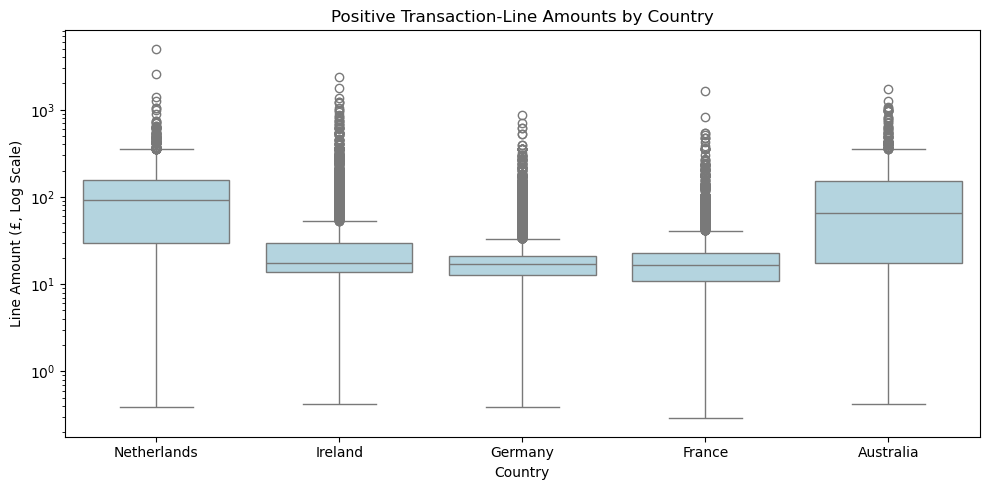

In [61]:
# Select the five leading overseas markets
top_countries = overseas_sales.head(5).index

# Select positive sales from these countries
country_data = eda[
    eda["country"].isin(top_countries)
    & (~eda["is_cancellation"])
]

# Compare transaction-line amounts across countries
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=country_data,
    x="country",
    y="line_amount",
    order=top_countries,
    color="lightblue"
)

# Use log scale to display small and large amounts
plt.yscale("log")

# Add chart title and labels
plt.title("Positive Transaction-Line Amounts by Country")
plt.xlabel("Country")
plt.ylabel("Line Amount (£, Log Scale)")
plt.tight_layout()
plt.show()

### Observations 
- The Netherlands has the highest median positive transaction-line amount, followed by Australia.
- Ireland, Germany, and France have lower, broadly similar medians.
- The Netherlands and Australia show greater variation in the middle 50% of transaction amounts.
- All five countries have high-value outliers. These may represent bulk purchases and are not automatically errors.
- The chart uses a logarithmic scale and excludes cancellations. It compares individual product-line amounts, not total sales or invoice values.

### Key Insights and Business Recommendations
1. Sales increased strongly from September to November.
   November 2011 had the highest monthly net product sales. Prepare stock and fulfilment capacity ahead of this period, but check additional years before assuming a recurring seasonal pattern.
2. Sales are heavily concentrated in the United Kingdom.
   The UK generated approximately £8.28 million. Maintain domestic service quality and assess margins, customer demand, and delivery costs before expanding overseas.
3. Cancellations reduced gross product sales by 4.64%.
   Investigate products and customers with high cancellation amounts to identify recurring issues.
4. Repeat purchasing is common among identified customers.
   Of 4,334 known purchasing customers, 65.27% had at least two purchase invoices. Review their spending and cancellation history before designing loyalty offers.

### Limitations
- Missing Customer IDs limit customer-level analysis.
- December 2011 contains only nine days of data.
- Two unresolved high-price records affect product rankings; excluding them reduces total net product sales by 0.41%.
- Product sales exclude identified fees, postage, discounts, and other special entries. They do not represent profit.
- The dataset covers approximately one year, limiting conclusions about recurring seasonality.

### Conclusion
The analysis identified sales trends, leading products and markets, cancellation impact, and repeat-purchase patterns. These findings support inventory planning and further customer analysis, subject to the stated data limitations.

# Task 3: Sales Prediction Model

Predict the next day's net product sales using historical sales and calendar features.

In [62]:
# Create a separate copy for model preparation
model_transactions = eda.copy()

# Extract the date without the time
model_transactions["date"] = (
    model_transactions["invoice_date"].dt.normalize()
)

# Add sales and cancellation amounts for each date
daily_sales = (
    model_transactions.groupby("date")["line_amount"]
    .sum()
    .to_frame(name="net_sales")
    .sort_index()
)

# Display the first five dates
display(daily_sales.head())

# Count dates with recorded transactions
print("Recorded dates:", len(daily_sales))

,net_sales
date,
2010-12-01,57194.60
2010-12-02,46055.32
2010-12-03,43465.65
2010-12-05,30546.96
2010-12-06,50801.25


Recorded dates: 305


### Observation — Daily Sales Preparation
- Transaction amounts were aggregated by date to calculate daily net product sales.
- The resulting table contains 305 dates with recorded transactions.
- Net product sales on December 1, 2010 were £57,194.60.
- Cancellation amounts were included as negative values.
- Some calendar dates, such as December 4, are absent and require investigation.

In [63]:
# Create every calendar date between the first and last recorded dates
all_dates = pd.date_range(
    start=daily_sales.index.min(),
    end=daily_sales.index.max(),
    freq="D"
)

# Find calendar dates absent from the daily table
missing_dates = all_dates.difference(daily_sales.index)

# Display the missing-date count
print("Missing calendar dates:", len(missing_dates))

# Display the first 15 missing dates
print(missing_dates[:15])

# Count missing dates by weekday
print("\nMissing dates by weekday:")
print(missing_dates.day_name().value_counts())

Missing calendar dates: 69
DatetimeIndex(['2010-12-04', '2010-12-11', '2010-12-18', '2010-12-24',
               '2010-12-25', '2010-12-26', '2010-12-27', '2010-12-28',
               '2010-12-29', '2010-12-30', '2010-12-31', '2011-01-01',
               '2011-01-02', '2011-01-03', '2011-01-08'],
              dtype='datetime64[ns]', freq=None)

Missing dates by weekday:
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64


### Observation — Missing Calendar Dates
- Identified 69 calendar dates without transaction records in the analysis subset.
- These include 53 Saturdays and 16 dates on other weekdays.
- The pattern suggests possible non-trading days, but their actual sales cannot be confirmed.
- Missing daily sales will remain unknown rather than being assumed to be zero.

In [64]:
# Add all calendar dates; keep unknown sales as NaN
daily_sales = daily_sales.reindex(all_dates)

# Name the date index
daily_sales.index.name = "date"

# Display the first 10 calendar dates
display(daily_sales.head(10))

# Check total dates and unknown daily sales
print("Total calendar dates:", len(daily_sales))
print("Dates with unknown sales:", daily_sales["net_sales"].isna().sum())

,net_sales
date,
2010-12-01,57194.60
2010-12-02,46055.32
2010-12-03,43465.65
2010-12-04,NaN
2010-12-05,30546.96
2010-12-06,50801.25
2010-12-07,81066.67
2010-12-08,43220.96
2010-12-09,49040.47


Total calendar dates: 374
Dates with unknown sales: 69


### Observation — Continuous Calendar Index
- Reindexed the daily sales table to include 374 consecutive calendar dates.
- Retained 69 unknown daily sales values as NaN, without assuming zero sales.
- The continuous date index enables lag features to represent actual calendar days.

In [65]:
# Create a separate copy for modeling
model_data = daily_sales.copy()

# Exclude the potentially incomplete final day
model_data = model_data.loc[
    model_data.index < pd.Timestamp("2011-12-09")
].copy()

# Add weekday: Monday = 0, Sunday = 6
model_data["day_of_week"] = model_data.index.dayofweek

# Add month: January = 1, December = 12
model_data["month"] = model_data.index.month

# Display the first five rows
display(model_data.head())

# Confirm the remaining date range
print("Calendar dates:", len(model_data))
print("Last date:", model_data.index.max())

,net_sales,day_of_week,month
date,,,
2010-12-01,57194.60,2,12
2010-12-02,46055.32,3,12
2010-12-03,43465.65,4,12
2010-12-04,NaN,5,12
2010-12-05,30546.96,6,12


Calendar dates: 373
Last date: 2011-12-08 00:00:00


### Observation — Calendar Features
- Excluded December 9, 2011 because it may contain incomplete daily records.
- The modeling table now contains 373 calendar dates, ending December 8, 2011.
- Added weekday and month as calendar features available before prediction.
- Unknown daily sales remain unchanged.

In [66]:
# Add sales from the previous calendar day
model_data["sales_lag_1"] = model_data["net_sales"].shift(1)

# Add sales from exactly seven calendar days earlier
model_data["sales_lag_7"] = model_data["net_sales"].shift(7)

# Average available sales from the previous seven calendar days
# Require at least four known daily values
model_data["sales_mean_7"] = (
    model_data["net_sales"]
    .shift(1)
    .rolling(window=7, min_periods=4)
    .mean()
)

# Display the first 12 rows
display(model_data.head(12))

,net_sales,day_of_week,month,sales_lag_1,sales_lag_7,sales_mean_7
date,,,,,,
2010-12-01,57194.60,2,12,NaN,NaN,NaN
2010-12-02,46055.32,3,12,57194.60,NaN,NaN
2010-12-03,43465.65,4,12,46055.32,NaN,NaN
2010-12-04,NaN,5,12,43465.65,NaN,NaN
2010-12-05,30546.96,6,12,NaN,NaN,NaN
2010-12-06,50801.25,0,12,30546.96,NaN,44315.632500
2010-12-07,81066.67,1,12,50801.25,NaN,45612.756000
2010-12-08,43220.96,2,12,81066.67,57194.60,51521.741667
2010-12-09,49040.47,3,12,43220.96,46055.32,49192.801667


### Observation — Historical Sales Features
- Created previous-day sales, seven-day lag sales, and a seven-day historical average.
- All features use information from dates before the prediction date.
- Missing history was preserved as NaN. The rolling average requires at least four known observations within the previous seven calendar days.

In [67]:
# Keep dates with known actual sales
# Preserve missing feature values for later preprocessing
model_ready = model_data.dropna(subset=["net_sales"]).copy()

# Find the position of the 80% split
split_point = int(len(model_ready) * 0.80)

# Use older dates for training
train = model_ready.iloc[:split_point].copy()

# Use later dates for testing
test = model_ready.iloc[split_point:].copy()

# Display row counts and date ranges
print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining dates:", train.index.min(), "to", train.index.max())
print("Testing dates:", test.index.min(), "to", test.index.max())

Training rows: 243
Testing rows: 61

Training dates: 2010-12-01 00:00:00 to 2011-09-28 00:00:00
Testing dates: 2011-09-29 00:00:00 to 2011-12-08 00:00:00


### Observation — Chronological Split
- Split 304 dates with known sales into 243 training records and 61 testing records.
- Training covers December 1, 2010 to September 28, 2011.
- Testing covers September 29, 2011 to December 8, 2011.
- Dates were not shuffled, preserving chronological order.

In [68]:
# Select the five input features
features = [
    "day_of_week",
    "month",
    "sales_lag_1",
    "sales_lag_7",
    "sales_mean_7"
]

# Prepare training inputs and target
X_train = train[features].copy()
y_train = train["net_sales"].copy()

# Prepare testing inputs and target
X_test = test[features].copy()
y_test = test["net_sales"].copy()

# Check input sizes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# Check missing values in training inputs
print("\nMissing training features:")
print(X_train.isna().sum())

X_train: (243, 5)
X_test: (61, 5)

Missing training features:
day_of_week      0
month            0
sales_lag_1     46
sales_lag_7     17
sales_mean_7    12
dtype: int64


### Observation — Features and Target
- Selected five features and separated net_sales as the target.
- Training features contain 46 missing previous-day values, 17 missing seven-day lag values, and 12 missing rolling averages.
- Calendar features contain no missing values.

In [69]:

# Identify calendar and historical sales features
calendar_columns = ["day_of_week", "month"]
sales_columns = ["sales_lag_1", "sales_lag_7", "sales_mean_7"]

# Prepare missing sales features using median and missing-value flags
sales_preparation = SimpleImputer(
    strategy="median",
    add_indicator=True
)

# Prepare calendar categories using one-hot encoding
calendar_preparation = OneHotEncoder(
    handle_unknown="ignore"
)

# Apply the appropriate preparation to each group of columns
preprocessor = ColumnTransformer([
    ("sales", sales_preparation, sales_columns),
    ("calendar", calendar_preparation, calendar_columns)
])

print("Preprocessing steps defined successfully!")

Preprocessing steps defined successfully!


In [70]:
# Import the regression model
from sklearn.linear_model import LinearRegression

# Combine preprocessing and the model
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

# Learn from training data only
linear_model.fit(X_train, y_train)

# Predict sales for the test dates
linear_predictions = linear_model.predict(X_test)

# Compare actual and predicted sales
linear_results = pd.DataFrame({
    "actual_sales": y_test,
    "predicted_sales": linear_predictions
})

# Display the first five predictions
display(linear_results.head().round(2))

,actual_sales,predicted_sales
date,,
2011-09-29,43133.50,45864.41
2011-09-30,42931.13,36845.37
2011-10-02,11520.61,15736.88
2011-10-03,60290.83,28348.70
2011-10-04,47027.87,40639.09


### Observation — Initial Linear Regression Predictions
- Trained Linear Regression using the training data and generated predictions for the testing dates.
- The first five predictions show both overestimation and underestimation.
- The model substantially underestimated sales on October 3, 2011.
- Overall performance must be assessed using all test records, rather than these five examples.


In [71]:
# Calculate the average absolute prediction error
linear_mae = mean_absolute_error(y_test, linear_predictions)

# Calculate RMSE, which gives more weight to large errors
linear_rmse = mean_squared_error(y_test, linear_predictions) ** 0.5

# Compare predictions with the test-set mean benchmark
linear_r2 = r2_score(y_test, linear_predictions)

# Display model performance
print("MAE (£):", round(linear_mae, 2))
print("RMSE (£):", round(linear_rmse, 2))
print("R²:", round(linear_r2, 3))

MAE (£): 15771.56
RMSE (£): 20920.24
R²: -0.327


### Observation — Linear Regression Performance
- Linear Regression produced an MAE of £15,771.56 and an RMSE of £20,920.24.
- The negative R² of −0.327 indicates poor performance relative to the test-set mean reference.
- RMSE exceeding MAE suggests that some predictions have large errors.
- The model requires comparison with a practical forecasting baseline and another regression model

In [72]:
# Use sales from seven calendar days earlier as the prediction
baseline_predictions = X_test["sales_lag_7"].copy()

# If unavailable, use the previous seven-day average
baseline_predictions = baseline_predictions.fillna(
    X_test["sales_mean_7"]
)

# If both are unavailable, use the training target median
baseline_predictions = baseline_predictions.fillna(y_train.median())

# Evaluate the baseline on the same test dates
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = mean_squared_error(y_test, baseline_predictions) ** 0.5
baseline_r2 = r2_score(y_test, baseline_predictions)

# Display baseline performance
print("Baseline MAE (£):", round(baseline_mae, 2))
print("Baseline RMSE (£):", round(baseline_rmse, 2))
print("Baseline R²:", round(baseline_r2, 3))

Baseline MAE (£): 14055.54
Baseline RMSE (£): 18165.08
Baseline R²: -0.0


### Observation — Baseline Comparison
- The weekly baseline achieved lower MAE and RMSE than Linear Regression.
- Its R² was approximately zero, indicating limited predictive performance.
- Linear Regression did not improve upon the simple forecasting baseline.

In [73]:
# Create an independent preprocessing-and-model pipeline
forest_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using training data only
forest_model.fit(X_train, y_train)

# Predict sales for the same test dates
forest_predictions = forest_model.predict(X_test)

# Evaluate the predictions
forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = mean_squared_error(y_test, forest_predictions) ** 0.5
forest_r2 = r2_score(y_test, forest_predictions)

# Display performance
print("Random Forest MAE (£):", round(forest_mae, 2))
print("Random Forest RMSE (£):", round(forest_rmse, 2))
print("Random Forest R²:", round(forest_r2, 3))

Random Forest MAE (£): 12916.91
Random Forest RMSE (£): 17245.74
Random Forest R²: 0.098


### Observation — Random Forest Performance
- Random Forest achieved the lowest MAE and RMSE among the three evaluated methods.
- MAE improved by approximately 8.1% compared with the weekly baseline.
- The R² of 0.098 indicates modest predictive performance.
- Further tuning will use training data only, with time-ordered validation.

In [74]:
# Create three expanding training-validation splits
time_cv = TimeSeriesSplit(n_splits=3)

# Display the date ranges used in each split
for fold, (train_idx, valid_idx) in enumerate(
    time_cv.split(X_train), start=1
):
    print(f"\nFold {fold}")

    print("Train:",
          X_train.index[train_idx].min().date(), "to",
          X_train.index[train_idx].max().date())

    print("Validation:",
          X_train.index[valid_idx].min().date(), "to",
          X_train.index[valid_idx].max().date())


Fold 1
Train: 2010-12-01 to 2011-02-22
Validation: 2011-02-23 to 2011-05-09

Fold 2
Train: 2010-12-01 to 2011-05-09
Validation: 2011-05-10 to 2011-07-19

Fold 3
Train: 2010-12-01 to 2011-07-19
Validation: 2011-07-20 to 2011-09-28


In [75]:


# Define settings to compare
parameter_grid = {
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [3, 5, 10]
}

# Compare settings using training data and time-based validation
search = GridSearchCV(
    estimator=forest_model,
    param_grid=parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=1
)

# Fit preprocessing and model separately within each validation fold
search.fit(X_train, y_train)

# Display the selected settings and average validation error
print("Best settings:", search.best_params_)
print("Best CV MAE (£):", round(-search.best_score_, 2))

Best settings: {'model__max_depth': 3, 'model__min_samples_leaf': 5}
Best CV MAE (£): 8354.23


In [76]:


# Define settings to compare
parameter_grid = {
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [3, 5, 10]
}

# Compare settings using training data and time-based validation
search = GridSearchCV(
    estimator=forest_model,
    param_grid=parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=1
)

# Fit preprocessing and model separately within each validation fold
search.fit(X_train, y_train)

# Display the selected settings and average validation error
print("Best settings:", search.best_params_)
print("Best CV MAE (£):", round(-search.best_score_, 2))

Best settings: {'model__max_depth': 3, 'model__min_samples_leaf': 5}
Best CV MAE (£): 8354.23


### Observation — Hyperparameter Tuning
- Time-based cross-validation selected a maximum tree depth of 3 and a minimum leaf size of 5.
- The mean validation MAE was £8,354.23.
- This validation score does not establish improvement on the final test period.

In [77]:
# Retrieve the best pipeline, already refitted on all training data
best_model = search.best_estimator_

# Predict sales for the unchanged test dates
tuned_predictions = best_model.predict(X_test)

# Calculate test performance
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = mean_squared_error(y_test, tuned_predictions) ** 0.5
tuned_r2 = r2_score(y_test, tuned_predictions)

# Display results
print("Tuned MAE (£):", round(tuned_mae, 2))
print("Tuned RMSE (£):", round(tuned_rmse, 2))
print("Tuned R²:", round(tuned_r2, 3))

Tuned MAE (£): 13149.24
Tuned RMSE (£): 17555.17
Tuned R²: 0.066


### Observation — Tuned Model Evaluation
- The tuned Random Forest performed slightly worse than the original Random Forest on the test period.
- Test MAE increased from £12,916.91 to £13,149.24.
- Hyperparameters were selected using training-period cross-validation, which did not guarantee improvement on later dates.
- Both models showed limited predictive performance.

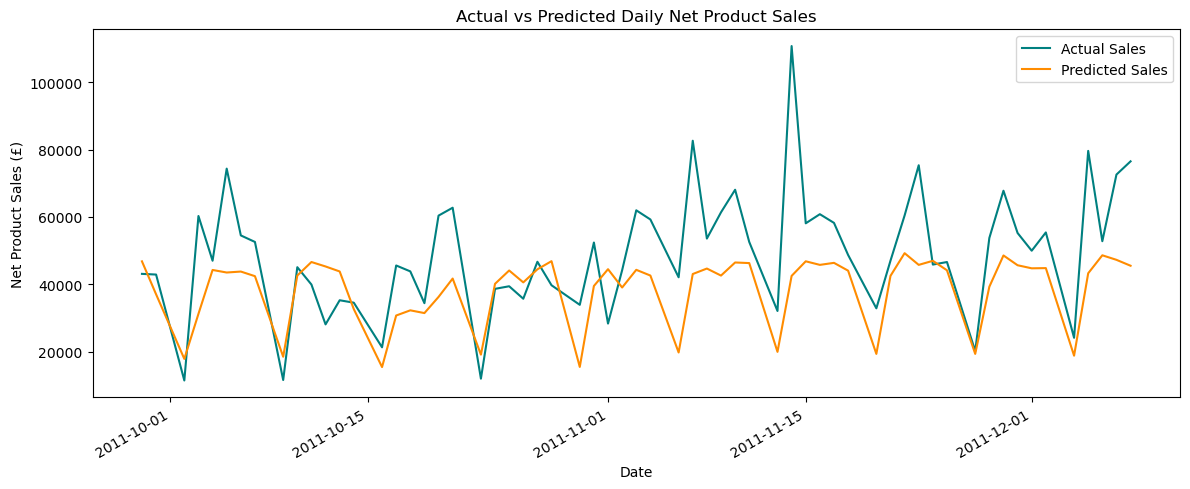

In [78]:
# Combine actual sales and tuned predictions by date
prediction_results = pd.DataFrame({
    "Actual Sales": y_test,
    "Predicted Sales": tuned_predictions
})

# Plot actual and predicted sales
prediction_results.plot(
    figsize=(12, 5),
    color=["teal", "darkorange"]
)

# Add chart title and labels
plt.title("Actual vs Predicted Daily Net Product Sales")
plt.xlabel("Date")
plt.ylabel("Net Product Sales (£)")
plt.tight_layout()
plt.show()

### Observation — Actual vs Predicted Sales
- The tuned Random Forest captures some recurring dips but produces less variable predictions than actual sales.
- It underestimates several high-sales days, particularly the largest November peak.
- This suggests difficulty capturing sudden increases in daily sales.
- The chart is consistent with the model’s modest test R² of 0.066.
- Predictions represent one-day-ahead estimates using previously available actual sales, rather than a single forecast for the entire test period.

calendar__day_of_week_6                0.384
sales__sales_mean_7                    0.316
sales__sales_lag_7                     0.147
sales__sales_lag_1                     0.041
sales__missingindicator_sales_lag_1    0.030
calendar__day_of_week_1                0.022
calendar__day_of_week_3                0.021
calendar__month_9                      0.020
calendar__month_12                     0.014
calendar__day_of_week_4                0.002
dtype: float64


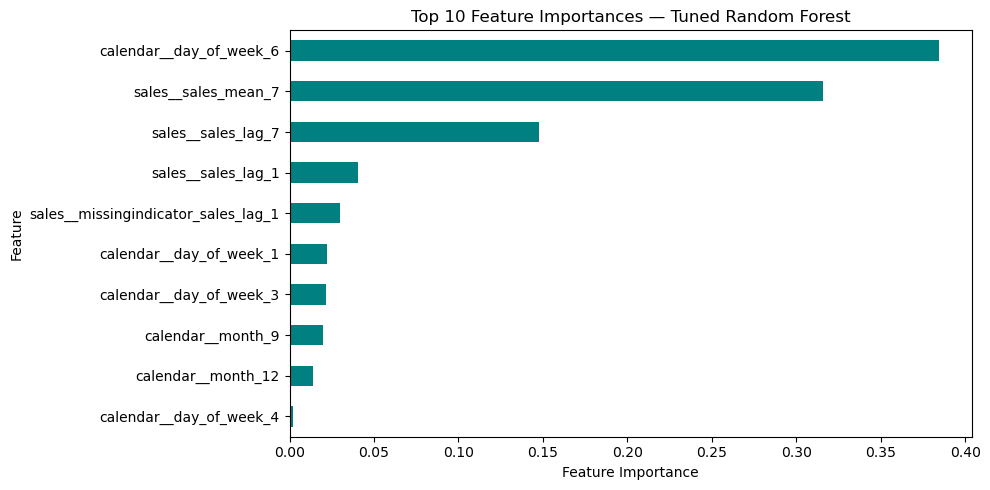

In [79]:
# Get feature names after preprocessing and encoding
feature_names = (
    best_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

# Get importance scores from the tuned Random Forest
importance_scores = (
    best_model.named_steps["model"].feature_importances_
)

# Arrange features from highest to lowest importance
feature_importance = pd.Series(
    importance_scores,
    index=feature_names
).sort_values(ascending=False)

# Display the ten most important features
print(feature_importance.head(10).round(3))

# Plot the ten most important features
feature_importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    color="teal"
)

# Add chart title and labels
plt.title("Top 10 Feature Importances — Tuned Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Observation — Feature Importance
- The Sunday indicator had the highest importance (0.384), followed by the seven-day historical sales average (0.316).
- Sales from seven days earlier (0.147) were more important than previous-day sales (0.041).
- The previous-day missing-value indicator also contributed, showing that missing-history patterns were useful to the model.
- These scores describe training-based split importance, not causation or the direction of an effect.
- High feature importance does not establish strong predictive performance; the model’s test R² remained 0.066

In [80]:
# Combine evaluation results for all methods
model_comparison = pd.DataFrame({
    "Model": [
        "Weekly Baseline",
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "MAE (£)": [
        baseline_mae, linear_mae, forest_mae, tuned_mae
    ],
    "RMSE (£)": [
        baseline_rmse, linear_rmse, forest_rmse, tuned_rmse
    ],
    "R2": [
        baseline_r2, linear_r2, forest_r2, tuned_r2
    ]
})

# Display models ordered by the lowest MAE
display(
    model_comparison.sort_values("MAE (£)").round(3)
)

,Model,MAE (£),RMSE (£),R2
2,Random Forest,12916.907,17245.743,0.098
3,Tuned Random Forest,13149.244,17555.166,0.066
0,Weekly Baseline,14055.544,18165.079,-0.000
1,Linear Regression,15771.562,20920.245,-0.327


## Model Performance Summary
- The original Random Forest achieved the lowest test MAE (£12,916.91) and RMSE (£17,245.74), with an R² of 0.098.
- Its MAE was approximately 8.1% lower than the weekly baseline.
- Hyperparameter tuning selected a shallower forest, but its test performance was slightly worse.
- Linear Regression performed worse than the weekly baseline.
- The models captured some recurring patterns but struggled to predict large sales peaks.

## Limitations
- Only 243 training dates and 61 test dates were available.
- Missing calendar-day sales were unknown and were not assumed to be zero. Evaluation covers only dates with known sales.
- Training-period medians were used to fill missing historical features, which may weaken forecasting signals.
- Promotions, holidays, and other potential demand drivers were not included.
- Unresolved high-price records and the treatment of special entries affect the target definition.
- Test performance was modest, so predictions should not be treated as reliable operational forecasts.
- Evaluation represents one-day-ahead predictions using previously observed actual sales, not a forecast of all 61 days at once.

## Conclusion
Random Forest improved upon the weekly baseline, but forecasting accuracy remained limited. More historical data, verified trading calendars, and additional demand-related features should be evaluated using time-based validation before operational use